Imports done!
Dataset shape: (641119, 12)
Features shape: (641119, 11)

Dataset split:
Training set:    (410316, 11)
Calibration set: (102579, 11)
Test set:        (128224, 11)

Ensemble weights:
Random Forest: 0.55
XGBoost: 0.45

Ensemble accuracy: 94.32%


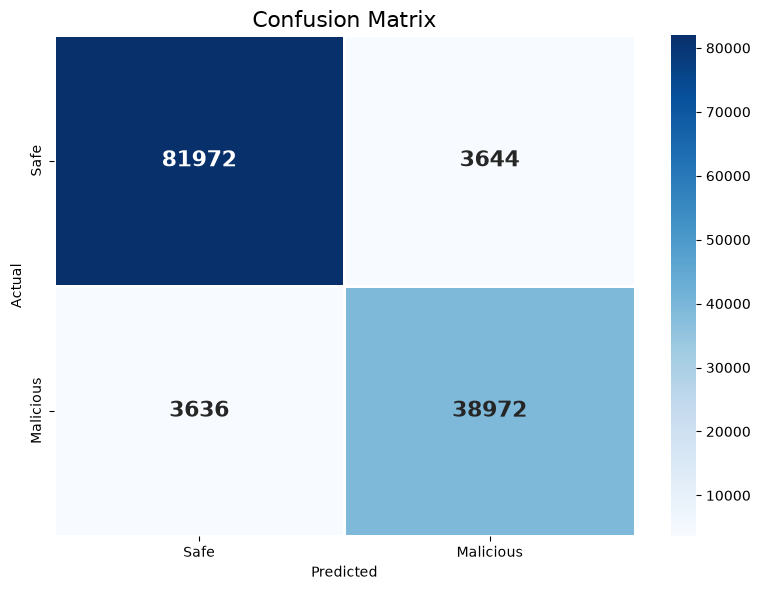


Confusion Matrix Counts:
TP: 38972 | TN: 81972 | FP: 3644 | FN: 3636


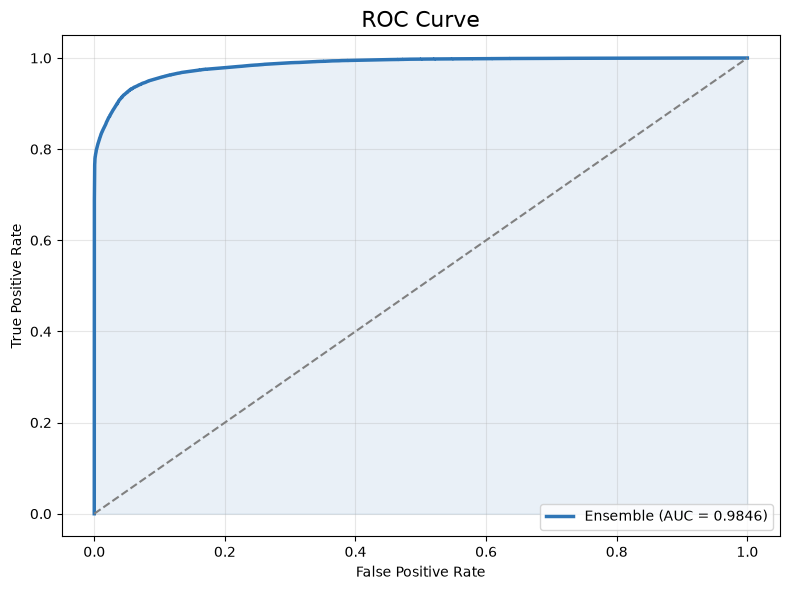

AUC-ROC: 0.9846

   FINAL EVALUATION SUMMARY
Accuracy:  94.32%
Precision: 91.45%
Recall:    91.47%
F1 Score:  0.9146
AUC-ROC:   0.9846

Evaluation complete!
Metrics saved to ../models/metrics.json
Confusion matrix saved to ../data/confusion_matrix.png
ROC curve saved to ../data/roc_curve.png


In [2]:

import pandas as pd
import numpy as np
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

print("Imports done!")

# ── Step 1: Load calibrated models and dataset ──
rf_model = joblib.load("../models/random_forest.pkl")
xgb_model = joblib.load("../models/xgboost.pkl")

df = pd.read_csv("../data/features.csv")

X = df.drop("label", axis=1)
y = df["label"]

print("Dataset shape:", df.shape)
print("Features shape:", X.shape)

# ── Step 2: Recreate the three-way split ──
# 64% training, 16% calibration, 20% testing

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("\nDataset split:")
print("Training set:   ", X_train.shape)
print("Calibration set:", X_calib.shape)
print("Test set:       ", X_test.shape)

# ── Step 3: Load ensemble configuration ──
with open("../models/ensemble_config.json", "r") as f:
    config = json.load(f)

RF_WEIGHT = config["rf_weight"]
XGB_WEIGHT = config["xgb_weight"]

print("\nEnsemble weights:")
print("Random Forest:", RF_WEIGHT)
print("XGBoost:", XGB_WEIGHT)

# ── Step 4: Generate ensemble predictions ──
rf_proba = rf_model.predict_proba(X_test)[:, 1]
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

ensemble_proba = (
    RF_WEIGHT * rf_proba
    + XGB_WEIGHT * xgb_proba
)

ensemble_pred = (ensemble_proba >= 0.5).astype(int)

print(
    f"\nEnsemble accuracy: "
    f"{accuracy_score(y_test, ensemble_pred) * 100:.2f}%"
)

# ── Step 5: Confusion matrix ──
cm = confusion_matrix(y_test, ensemble_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Safe", "Malicious"],
    yticklabels=["Safe", "Malicious"],
    linewidths=2,
    annot_kws={"size": 16, "weight": "bold"}
)

plt.title("Confusion Matrix", fontsize=16)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()

plt.savefig(
    "../data/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("\nConfusion Matrix Counts:")
print(f"TP: {tp} | TN: {tn} | FP: {fp} | FN: {fn}")

# ── Step 6: ROC curve and AUC ──
fpr, tpr, thresholds = roc_curve(y_test, ensemble_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color="#2E75B6",
    linewidth=2.5,
    label=f"Ensemble (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--"
)

plt.fill_between(
    fpr,
    tpr,
    alpha=0.1,
    color="#2E75B6"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve", fontsize=16)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../data/roc_curve.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print(f"AUC-ROC: {roc_auc:.4f}")

# ── Step 7: Final evaluation metrics ──
accuracy = accuracy_score(y_test, ensemble_pred)
precision = precision_score(
    y_test, ensemble_pred, zero_division=0
)
recall = recall_score(
    y_test, ensemble_pred, zero_division=0
)
f1 = f1_score(
    y_test, ensemble_pred, zero_division=0
)

print("\n" + "=" * 40)
print("   FINAL EVALUATION SUMMARY")
print("=" * 40)
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1:.4f}")
print(f"AUC-ROC:   {roc_auc:.4f}")

# ── Step 8: Save metrics ──
metrics = {
    "accuracy": round(accuracy, 4),
    "precision": round(precision, 4),
    "recall": round(recall, 4),
    "f1_score": round(f1, 4),
    "auc_roc": round(roc_auc, 4)
}

with open("../models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("\nEvaluation complete!")
print("Metrics saved to ../models/metrics.json")
print("Confusion matrix saved to ../data/confusion_matrix.png")
print("ROC curve saved to ../data/roc_curve.png")
